# Фандинг, страх и жадность

Ноутбук заново собирает пост про отрицательный фандинг биткоина.

Выполни все ячейки сверху вниз (Run All). Чтобы сдвинуть окно или пороги, правь только следующую ячейку. Текст поста в конце пересчитается сам.

На окне по умолчанию пост совпадает со скриншотом:

- экстремальный страх, индекс < 20: T = −0.32, p = 0.75
- экстремальная жадность, индекс > 70: T = 1.2, p = 0.22
- отрицательный фандинг: T = 2.1, p = 0.035
- средняя доходность следующего дня 0.75% против 0.09% при положительном фандинге

В подписи на скриншоте порог жадности записан как «index > 80». Цифры 1.2 и 0.22 даёт порог 70. При пороге 80 получается другой тест, около T = 1.7 и p = 0.08.

Это описание уже посчитанного теста, не инвестиционная рекомендация.


## Параметры

`START` и `END` включительно. Чтобы посчитать по всем дням, которые сейчас есть в трёх источниках, поставь `END = None`.


In [1]:
# Окно, на котором собран пост от сентября 2024.
START = "2020-01-21"
END = "2024-09-09"  # None — последний день, общий для цены, индекса и фандинга

# Экстремальный страх и экстремальная жадность.
FEAR_BELOW = 20
GREED_ABOVE = 70

# Локальные снимки на случай, если источник не ответит.
DATA_DIR = "data"


## Что именно сравнивается

На каждый день t берутся три вещи:

- дневной close BTC-USD;
- индекс страха и жадности за этот UTC-день;
- последний 8-часовой фандинг бессрочного BTCUSDT на Binance за этот UTC-день.

Доходность следующего дня — `close(t+1) / close(t) - 1` по строкам выборки. У последнего дня в окне следующего close внутри окна нет, поэтому его доходность пустая. Так же был устроен исходный расчёт, и за счёт этого сходятся опубликованные T и p.

Тест — Уэлч (дисперсии не предполагаются равными). Средняя и дисперсия группы сравниваются со средней и дисперсией всей выборки, включая саму группу. В старом ноутбуке было несколько вариантов t-теста. В пост попал этот.

Пороги: индекс < 20, индекс > 70, фандинг <= 0 и фандинг >= 0. День с фандингом ровно 0 попал бы в обе фандинговые группы. На этом ряду таких дней нет.


In [2]:
from __future__ import annotations

import io
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf
from IPython.display import Image, display
from scipy import stats

plt.rcParams["figure.figsize"] = (11, 4.8)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 12

FUNDING_URL = (
    "https://data.binance.vision/data/futures/um/monthly/fundingRate/"
    "BTCUSDT/BTCUSDT-fundingRate-{month}.zip"
)
SESSION = requests.Session()
SESSION.headers["User-Agent"] = "funding-fear-greed-notebook/1.0"


def month_spans(first: pd.Timestamp, last: pd.Timestamp):
    year, month = first.year, first.month
    while (year, month) <= (last.year, last.month):
        yield year, month
        month += 1
        if month == 13:
            year += 1
            month = 1


def fetch_bytes(url: str) -> requests.Response:
    last_error: Exception | None = None
    for attempt in range(3):
        try:
            response = SESSION.get(url, timeout=60)
        except requests.RequestException as exc:
            last_error = exc
            continue
        if response.status_code in {429, 500, 502, 503, 504} and attempt < 2:
            continue
        return response
    raise RuntimeError(f"Не удалось скачать {url}: {last_error}")


def read_funding_zip(payload: bytes) -> pd.DataFrame:
    archive = zipfile.ZipFile(io.BytesIO(payload))
    frame = pd.read_csv(archive.open(archive.namelist()[0]))
    frame["ts"] = pd.to_datetime(frame["calc_time"], unit="ms", utc=True)
    frame["funding_rate"] = pd.to_numeric(frame["last_funding_rate"])
    frame["date"] = frame["ts"].dt.tz_convert("UTC").dt.normalize().dt.tz_localize(None)
    return frame


def load_funding(data_dir: Path) -> pd.DataFrame:
    path = data_dir / "binance_btcusdt_funding_daily.csv"
    first = pd.Timestamp("2020-01-01")
    last = pd.Timestamp.today().normalize()
    months = list(month_spans(first, last))
    print(f"Фандинг Binance BTCUSDT: {len(months)} месячных файлов")

    def one(item: tuple[int, int]):
        year, month = item
        label = f"{year:04d}-{month:02d}"
        response = fetch_bytes(FUNDING_URL.format(month=label))
        return label, response.status_code, response.content

    try:
        with ThreadPoolExecutor(max_workers=8) as pool:
            downloaded = list(pool.map(one, months))
    except Exception as exc:
        if not path.exists():
            raise
        print(f"Архив Binance не ответил ({exc}). Беру снимок {path}.")
        cached = pd.read_csv(path, parse_dates=["date"])
        return cached

    frames = []
    ok_months = []
    missing_months = []
    for label, status, payload in downloaded:
        if status == 404:
            missing_months.append(label)
            continue
        if status != 200:
            if path.exists():
                print(f"{label}: HTTP {status}. Беру снимок {path}.")
                return pd.read_csv(path, parse_dates=["date"])
            raise RuntimeError(f"Фандинг {label}: HTTP {status}")
        ok_months.append(label)
        frames.append(read_funding_zip(payload))
    if ok_months:
        holes = [label for label in missing_months if label < ok_months[-1]]
        if holes:
            print("В архиве нет месяцев внутри истории:", ", ".join(holes))

    if not frames:
        if path.exists():
            print(f"Пустой ответ архива. Беру снимок {path}.")
            return pd.read_csv(path, parse_dates=["date"])
        raise RuntimeError("Binance не отдал ни одного месяца фандинга.")

    prints = pd.concat(frames, ignore_index=True)
    daily = (
        prints.sort_values("ts")
        .groupby("date", as_index=False)
        .agg(funding_rate=("funding_rate", "last"))
    )
    data_dir.mkdir(parents=True, exist_ok=True)
    daily.to_csv(path, index=False)
    print(
        f"Фандинг {daily['date'].min().date()} — {daily['date'].max().date()}: "
        f"{len(daily)} дней"
    )
    return daily


def load_fear_greed(data_dir: Path) -> pd.DataFrame:
    path = data_dir / "fear_greed.csv"
    try:
        response = fetch_bytes("https://api.alternative.me/fng/?limit=0&format=json")
        response.raise_for_status()
        rows = []
        for entry in response.json()["data"]:
            stamp = pd.to_datetime(int(entry["timestamp"]), unit="s", utc=True)
            day = stamp.tz_convert("UTC").normalize().tz_localize(None)
            rows.append((day, int(entry["value"])))
        frame = pd.DataFrame(rows, columns=["date", "fear_greed"])
        frame = frame.drop_duplicates("date").sort_values("date")
        data_dir.mkdir(parents=True, exist_ok=True)
        frame.to_csv(path, index=False)
    except Exception as exc:
        if not path.exists():
            raise
        print(f"Индекс страха и жадности не ответил ({exc}). Беру снимок {path}.")
        frame = pd.read_csv(path, parse_dates=["date"])
    print(
        f"Индекс {frame['date'].min().date()} — {frame['date'].max().date()}: "
        f"{len(frame)} дней"
    )
    return frame


def normalize_price(raw: pd.DataFrame) -> pd.DataFrame:
    if raw is None or len(raw) == 0:
        raise RuntimeError("Yahoo Finance вернул пустой ряд BTC-USD.")
    if isinstance(raw.columns, pd.MultiIndex):
        raw = raw.copy()
        raw.columns = raw.columns.get_level_values(0)
    close = raw[["Close"]].copy()
    index = pd.to_datetime(close.index)
    if getattr(index, "tz", None) is not None:
        index = index.tz_convert("UTC").tz_localize(None)
    close.index = index.normalize()
    frame = close.reset_index()
    date_column = "Date" if "Date" in frame.columns else frame.columns[0]
    frame = frame.rename(columns={date_column: "date", "Close": "close"})
    frame["date"] = pd.to_datetime(frame["date"]).dt.normalize()
    return frame.drop_duplicates("date").sort_values("date")


def load_btc(start: pd.Timestamp, end: pd.Timestamp, data_dir: Path) -> pd.DataFrame:
    path = data_dir / "btc_usd_daily.csv"
    try:
        wide_end = (pd.Timestamp.today().normalize() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
        raw = yf.download(
            "BTC-USD",
            start="2020-01-01",
            end=wide_end,
            auto_adjust=False,
            progress=False,
        )
        frame = normalize_price(raw)
        data_dir.mkdir(parents=True, exist_ok=True)
        frame.to_csv(path, index=False)
    except Exception as exc:
        if not path.exists():
            raise
        print(f"Yahoo Finance не ответил ({exc}). Беру снимок {path}.")
        frame = pd.read_csv(path, parse_dates=["date"])
    window = frame[(frame["date"] >= start) & (frame["date"] <= end)].copy()
    if window.empty:
        raise RuntimeError("В ряде BTC-USD нет дней внутри выбранного окна.")
    print(f"BTC-USD {window['date'].min().date()} — {window['date'].max().date()}: {len(window)} дней")
    return window[["date", "close"]]


## Сборка выборки


In [3]:
data_dir = Path(DATA_DIR)
requested_end = None if END in (None, "") else pd.Timestamp(END)
start = pd.Timestamp(START)

funding = load_funding(data_dir)
fear = load_fear_greed(data_dir)
price_end = requested_end or min(funding["date"].max(), fear["date"].max())
btc = load_btc(start, price_end, data_dir)

sample = btc.merge(fear, on="date", how="inner").merge(funding, on="date", how="inner")
sample = sample[sample["date"] >= start].sort_values("date")
if requested_end is not None:
    sample = sample[sample["date"] <= requested_end]
sample = sample.dropna(subset=["close", "fear_greed", "funding_rate"]).reset_index(drop=True)

if sample.empty:
    raise RuntimeError("После склейки источников не осталось ни одного дня.")

# Доходность следующего дня внутри уже отфильтрованного окна.
sample["next_day_return"] = sample["close"].pct_change().shift(-1)
sample["extreme_fear"] = sample["fear_greed"] < FEAR_BELOW
sample["extreme_greed"] = sample["fear_greed"] > GREED_ABOVE
sample["negative_funding"] = sample["funding_rate"] <= 0
sample["positive_funding"] = sample["funding_rate"] >= 0

zero_funding_days = int((sample["funding_rate"] == 0).sum())
print(
    f"Выборка {sample['date'].min().date()} — {sample['date'].max().date()}: "
    f"{len(sample)} дней"
)
print(
    f"Страх: {int(sample['extreme_fear'].sum())} дней, "
    f"жадность: {int(sample['extreme_greed'].sum())}, "
    f"фандинг < 0: {int(sample['negative_funding'].sum())}, "
    f"фандинг > 0: {int((sample['funding_rate'] > 0).sum())}, "
    f"фандинг = 0: {zero_funding_days}"
)
sample[["date", "close", "fear_greed", "funding_rate", "next_day_return"]].tail(3)


Фандинг Binance BTCUSDT: 82 месячных файлов


Фандинг 2020-01-01 — 2026-09-30: 2465 дней


Индекс 2018-02-01 — 2026-10-21: 3181 дней


BTC-USD 2020-01-21 — 2024-09-09: 1694 дней
Выборка 2020-01-21 — 2024-09-09: 1694 дней
Страх: 138 дней, жадность: 413, фандинг < 0: 206, фандинг > 0: 1488, фандинг = 0: 0


,date,close,fear_greed,funding_rate,next_day_return
1691,2024-09-07,54139.687500,23,-0.000072,0.012964
1692,2024-09-08,54841.566406,29,-0.000052,0.039714
1693,2024-09-09,57019.535156,26,-0.000039,NaN


## T-тесты

Первая таблица — то сравнение, которое напечатано в посте: группа против всей выборки.

Вторая таблица — группа против остальных дней. В старом ноутбуке она тоже считалась и давала другие p-value. В пост она не вошла. Она лежит здесь, чтобы следующее изменение теста не пришлось искать по чужим ячейкам.


In [4]:
def welch(group: pd.Series, group_nobs: int, reference: pd.Series, reference_nobs: int):
    t_stat, p_value = stats.ttest_ind_from_stats(
        mean1=group.mean(),
        std1=group.std(ddof=1),
        nobs1=group_nobs,
        mean2=reference.mean(),
        std2=reference.std(ddof=1),
        nobs2=reference_nobs,
        equal_var=False,
    )
    return float(t_stat), float(p_value)


def row_against_sample(name: str, mask: pd.Series) -> dict:
    group = sample.loc[mask, "next_day_return"]
    t_stat, p_value = welch(group, int(mask.sum()), sample["next_day_return"], len(sample))
    return {
        "условие": name,
        "дней": int(mask.sum()),
        "средняя доходность следующего дня": group.mean(),
        "t": t_stat,
        "p": p_value,
    }


def row_against_rest(name: str, mask: pd.Series) -> dict:
    group = sample.loc[mask, "next_day_return"]
    rest = sample.loc[~mask, "next_day_return"]
    t_stat, p_value = welch(group, int(mask.sum()), rest, int((~mask).sum()))
    return {
        "условие": name,
        "дней": int(mask.sum()),
        "средняя в группе": group.mean(),
        "средняя в остальные дни": rest.mean(),
        "t": t_stat,
        "p": p_value,
    }


CONDITIONS = [
    (f"Страх, индекс < {FEAR_BELOW}", sample["extreme_fear"]),
    (f"Жадность, индекс > {GREED_ABOVE}", sample["extreme_greed"]),
    ("Отрицательный фандинг", sample["negative_funding"]),
    ("Положительный фандинг", sample["positive_funding"]),
]

published = pd.DataFrame([row_against_sample(name, mask) for name, mask in CONDITIONS])
published["значимо на 5%"] = published["p"] < 0.05
against_rest = pd.DataFrame([row_against_rest(name, mask) for name, mask in CONDITIONS])

def show_table(frame: pd.DataFrame, percent_columns: list[str]) -> None:
    view = frame.copy()
    for column in percent_columns:
        view[column] = view[column].map(lambda value: f"{value:.2%}")
    for column in ("t", "p"):
        view[column] = view[column].map(lambda value: f"{value:.4f}")
    display(view)


print("Группа против всей выборки. Эти строки собирают пост.")
show_table(published, ["средняя доходность следующего дня"])
print("Группа против остальных дней. Эти p-value в пост не входили.")
show_table(against_rest, ["средняя в группе", "средняя в остальные дни"])


Группа против всей выборки. Эти строки собирают пост.


,условие,дней,средняя доходность следующего дня,t,p,значимо на 5%
0,"Страх, индекс < 20",138,0.02%,-0.3225,0.7476,False
1,"Жадность, индекс > 70",413,0.40%,1.2087,0.2272,False
2,Отрицательный фандинг,206,0.75%,2.1102,0.0358,True
3,Положительный фандинг,1488,0.09%,-0.6671,0.5048,False


Группа против остальных дней. Эти p-value в пост не входили.


,условие,дней,средняя в группе,средняя в остальные дни,t,p
0,"Страх, индекс < 20",138,0.02%,0.18%,-0.3514,0.7258
1,"Жадность, индекс > 70",413,0.40%,0.10%,1.5561,0.1201
2,Отрицательный фандинг,206,0.75%,0.09%,2.3902,0.0176
3,Положительный фандинг,1488,0.09%,0.75%,-2.3902,0.0176


## Доходности, из которых состоит вывод


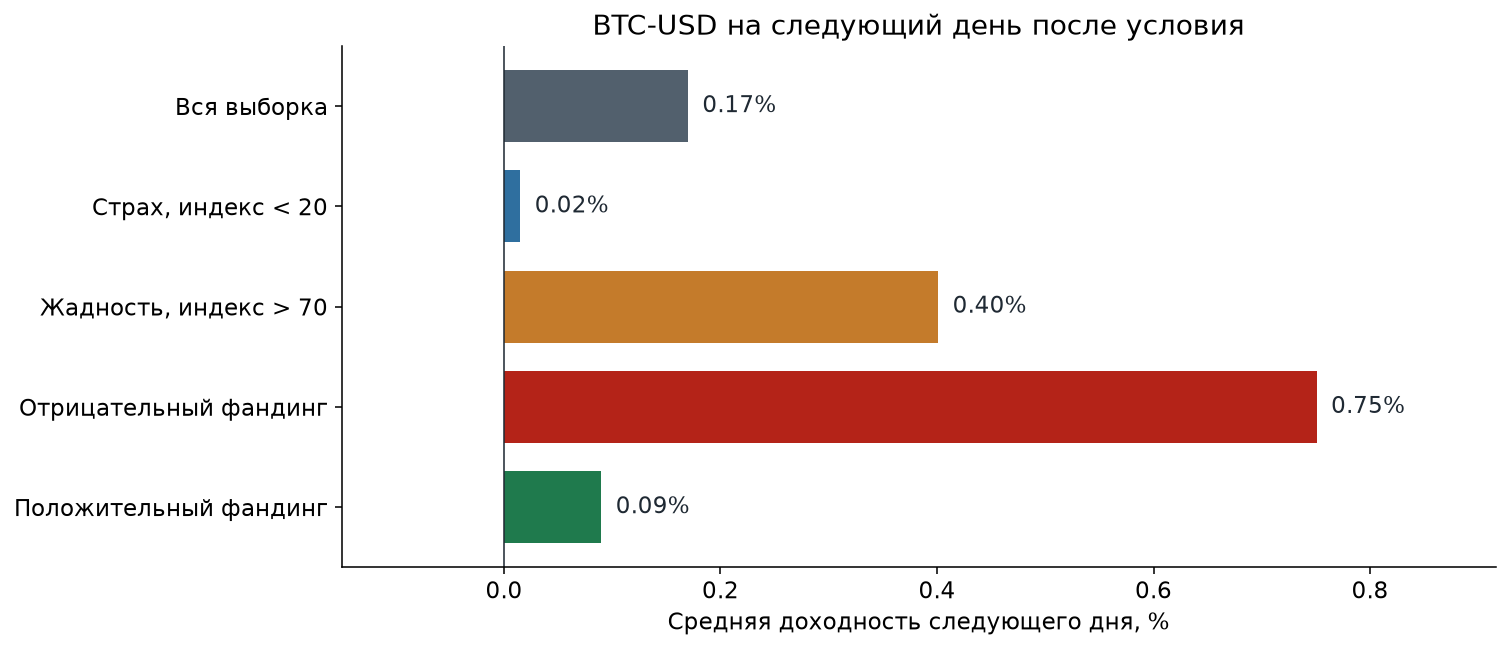

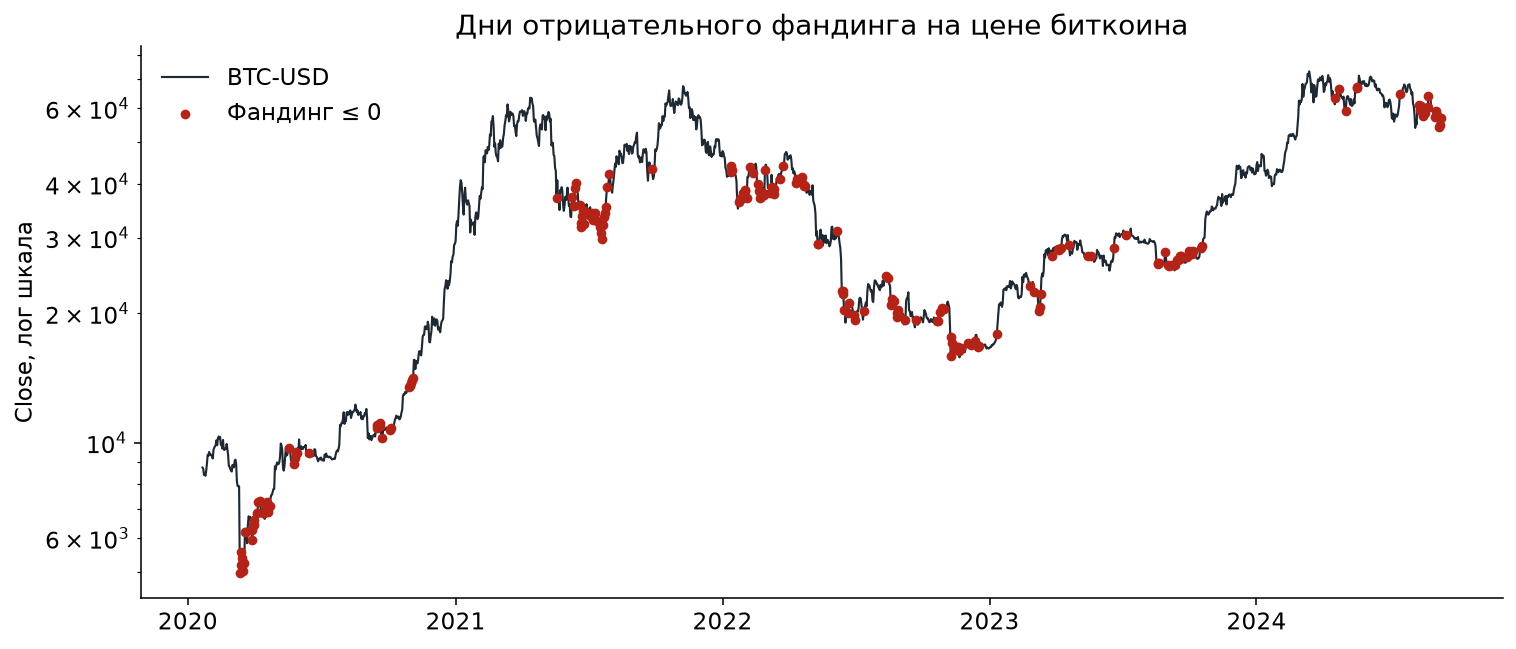

In [5]:
means = [("Вся выборка", sample["next_day_return"].mean(), "#52606d")]
means.extend(
    (
        name,
        sample.loc[mask, "next_day_return"].mean(),
        color,
    )
    for (name, mask), color in zip(
        CONDITIONS,
        ["#2f6f9f", "#c47b2b", "#b42318", "#1f7a4d"],
    )
)

def show_figure(figure: plt.Figure) -> None:
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)


figure, axis = plt.subplots()
labels = [item[0] for item in means]
values = [item[1] * 100 for item in means]
colors = [item[2] for item in means]
positions = np.arange(len(labels))
bars = axis.barh(positions, values, color=colors, height=0.72)
axis.axvline(0, color="#1f2933", lw=0.8)
axis.set_yticks(positions, labels)
axis.set_xlabel("Средняя доходность следующего дня, %")
axis.set_title("BTC-USD на следующий день после условия")
axis.invert_yaxis()
span = max(values) - min(0, min(values))
pad = max(0.12, span * 0.22)
for bar, value in zip(bars, values):
    axis.text(
        value + pad * 0.08,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        ha="left",
        color="#1f2933",
    )
axis.set_xlim(min(0, min(values) - pad), max(values) + pad)
figure.tight_layout()
show_figure(figure)

figure, axis = plt.subplots()
axis.plot(sample["date"], sample["close"], color="#1f2933", lw=1.1, label="BTC-USD")
negative = sample[sample["negative_funding"]]
axis.scatter(
    negative["date"],
    negative["close"],
    s=16,
    color="#b42318",
    zorder=3,
    label="Фандинг ≤ 0",
)
axis.set_yscale("log")
axis.set_ylabel("Close, лог шкала")
axis.set_title("Дни отрицательного фандинга на цене биткоина")
axis.legend(frameon=False, loc="upper left")
figure.tight_layout()
show_figure(figure)


## Текст поста

Числа в тексте округлены как на скриншоте. T от 1 по модулю показан с одним знаком, T меньше 1 — с двумя. p ниже 0.05 обрезан до трёх знаков: 0.0358 записано как 0.035.

p жадности в таблице около 0.227. Обычное округление до двух знаков даёт 0.23, на скриншоте написано 0.22. Для исходного окна в тексте поста остаётся 0.22.

«В 8 раз» — отношение уже округлённых процентов 0.75 и 0.09.


In [6]:
def post_t(value: float) -> str:
    if abs(value) >= 1:
        return f"{value:.1f}"
    return f"{value:.2f}"


def post_p(value: float) -> str:
    if value < 0.05:
        # 0.0358 в посте записан как 0.035: третий знак оставили, четвёртый отбросили.
        truncated = int(value * 1000) / 1000
        return f"{truncated:.3f}"
    return f"{value:.2f}"


def percent_label(mean: float) -> str:
    return f"{mean * 100:.2f}%"


by_name = {row["условие"]: row for row in published.to_dict("records")}
fear = by_name[f"Страх, индекс < {FEAR_BELOW}"]
greed = by_name[f"Жадность, индекс > {GREED_ABOVE}"]
negative = by_name["Отрицательный фандинг"]
positive = by_name["Положительный фандинг"]


def fear_verdict(result: dict) -> str:
    if result["p"] >= 0.05:
        return "Price behaves as usual. Sorry, Buffett!"
    if result["t"] > 0:
        return "Fear days are followed by a larger next-day rise than the sample average."
    return "Fear days are followed by a weaker next-day return than the sample average."


def greed_verdict(result: dict) -> str:
    if result["p"] >= 0.05:
        return "No magic here either. Just normal price behavior."
    if result["t"] > 0:
        return "Greed days are followed by a larger next-day rise than the sample average."
    return "Greed days are followed by a weaker next-day return than the sample average."


def funding_verdict(result: dict) -> str:
    if result["p"] < 0.05 and result["t"] > 0:
        return "BINGO! Statistically significant daily price change increase!"
    if result["p"] < 0.05:
        return "Statistically significant, but the next-day return is lower than the sample average."
    return "No statistically significant difference from the sample average."


negative_pct = round(negative["средняя доходность следующего дня"] * 100, 2)
positive_pct = round(positive["средняя доходность следующего дня"] * 100, 2)
if positive_pct > 0 and negative_pct > 0:
    times = round(negative_pct / positive_pct)
    insight = (
        f"Key Insight: With negative funding, price daily rises on average by "
        f"{negative_pct:.2f}%, which is {times} times more than with positive funding "
        f"({positive_pct:.2f}%)!"
    )
else:
    times = None
    insight = (
        "Key Insight: Average next-day return is "
        f"{percent_label(negative['средняя доходность следующего дня'])} after negative funding "
        f"and {percent_label(positive['средняя доходность следующего дня'])} after positive funding."
    )

published_window = (
    str(START) == "2020-01-21"
    and str(END) == "2024-09-09"
    and FEAR_BELOW == 20
    and GREED_ABOVE == 70
)
# На скриншоте p жадности записан как 0.22. Сырое значение около 0.227,
# обычное округление до двух знаков даёт 0.23. В тексте поста для исходного окна
# остаётся цифра со скриншота, точное p стоит в таблице выше.
greed_p_text = "0.22" if published_window else post_p(greed["p"])

bingo = negative["p"] < 0.05 and negative["t"] > 0
spoiler = (
    "(Spoiler: negative funding is our bro!)"
    if bingo
    else "(Spoiler: the old slogan does not survive this window.)"
)
conclusion = (
    "Conclusion: Hamsters, prepare to be sheared! Negative funding is our "
    "true friend in the crypto trading world."
    if bingo
    else "Conclusion: On this window the negative-funding slogan from the old post does not hold."
)

start_label = sample["date"].min().date().isoformat()
end_label = sample["date"].max().date().isoformat()
post = f'''FEAR & GREED INDEX vs FUNDING RATE: BATTLE OF THE TITANS!

"Be fearful when others are greedy and greedy when others are fearful" - Warren Buffett
"Mass shorts = liquidation of hamsters" - Crypto traders

Let's test these claims with t-tests from math stats!
{spoiler}

Extreme Fear (index < {FEAR_BELOW}):
T-stats: {post_t(fear["t"])}, P-value: {post_p(fear["p"])}
Verdict: {fear_verdict(fear)}

Extreme Greed (index > {GREED_ABOVE}):
T-stats: {post_t(greed["t"])}, P-value: {greed_p_text}
Verdict: {greed_verdict(greed)}

Negative Funding (funding rate < 0):
T-stats: {post_t(negative["t"])}, P-value: {post_p(negative["p"])}
Verdict: {funding_verdict(negative)}

{insight}

{conclusion}

#Cryptocurrencies #Bitcoin #TradingStrategies #DataScience #Trading #fintech #cryptoinvesting #crypto #investingtips #cryptotip

P.S. Data {start_label} to {end_label}. Funding from Binance BTCUSDT perpetual (last print of each UTC day), fear and greed index from alternative.me. Each t-test compares next-day BTC-USD returns on the selected days with the average next-day return of the whole sample. Not investment advice, DYOR!
'''
print(post)

expected = {
    "fear": ("-0.32", "0.75"),
    "greed": ("1.2", "0.22"),
    "funding": ("2.1", "0.035"),
    "negative_return": "0.75%",
    "positive_return": "0.09%",
    "times": 8,
}
actual = {
    "fear": (post_t(fear["t"]), post_p(fear["p"])),
    "greed": (post_t(greed["t"]), greed_p_text),
    "funding": (post_t(negative["t"]), post_p(negative["p"])),
    "negative_return": f"{negative_pct:.2f}%",
    "positive_return": f"{positive_pct:.2f}%",
    "times": times,
}
if published_window:
    mismatches = {key: (actual[key], expected[key]) for key in expected if actual[key] != expected[key]}
    if mismatches:
        print("Сверка с постом не сошлась:", mismatches)
    else:
        print("Сверка с постом: все округлённые цифры совпали.")
    print(
        f"p жадности в таблице: {greed['p']:.4f}. "
        "На скриншоте оно записано как 0.22; округление до двух знаков даёт 0.23."
    )
else:
    print("Окно или пороги изменены, сверка с постом сентября 2024 пропущена.")


FEAR & GREED INDEX vs FUNDING RATE: BATTLE OF THE TITANS!

"Be fearful when others are greedy and greedy when others are fearful" - Warren Buffett
"Mass shorts = liquidation of hamsters" - Crypto traders

Let's test these claims with t-tests from math stats!
(Spoiler: negative funding is our bro!)

Extreme Fear (index < 20):
T-stats: -0.32, P-value: 0.75
Verdict: Price behaves as usual. Sorry, Buffett!

Extreme Greed (index > 70):
T-stats: 1.2, P-value: 0.22
Verdict: No magic here either. Just normal price behavior.

Negative Funding (funding rate < 0):
T-stats: 2.1, P-value: 0.035
Verdict: BINGO! Statistically significant daily price change increase!

Key Insight: With negative funding, price daily rises on average by 0.75%, which is 8 times more than with positive funding (0.09%)!

Conclusion: Hamsters, prepare to be sheared! Negative funding is our true friend in the crypto trading world.

#Cryptocurrencies #Bitcoin #TradingStrategies #DataScience #Trading #fintech #cryptoinvesting 

## Что менять дальше

- Другой конец истории: поставь `END = None` и выполни ноутбук ещё раз. Фандинг в публичном архиве Binance появляется месячным файлом после закрытия месяца.
- Другой порог жадности: поменяй `GREED_ABOVE`. Значение 80 — это подпись со скриншота, не тот порог, которым посчитаны 1.2 и 0.22.
- Вторая таблица сравнивает группу с остальными днями. Пост читает первую таблицу. Это другой тест: у отрицательного фандинга там p около 0.018, не 0.035.
